#CS156 Session 16 — Dimensionality Reduction 1: PCA
##Core Questions — Eigenfashion Challenge
Research question: Can principal component analysis (PCA) represent photographs of T-shirts and shirts using fewer features while preserving enough information to help distinguish the two categories?

I use 100 T-shirt photographs and 100 shirt photographs (200 total). The original course-hosted ImageNet links are inaccessible, so I use the public Hugging Face ashraq/fashion-product-images-small dataset as a replacement, not the original ImageNet files.

My steps are to load the photographs, crop and resize them to 48 × 48 pixels, convert them to arrays, fit PCA on training images, select enough principal components for at least 95% training variance, and compare reconstructions. I also test a logistic regression classifier using the reduced features.

PCA is unsupervised: it does not use the labels to find its principal components. I use the labels only for plotting and classification.

Step 1 — Loading the clothing photographs
I select 100 images from each class. For each image, I convert the photograph to RGB, center-crop it to a square, resize it to 48 × 48 pixels, and scale its pixel values from 0 to 1. Center cropping avoids stretching images, although it may remove some content around their edges.

Images per category: {'Tshirts': 100, 'Shirts': 100}
Image array: (200, 48, 48, 3)
PCA input: (200, 6912)


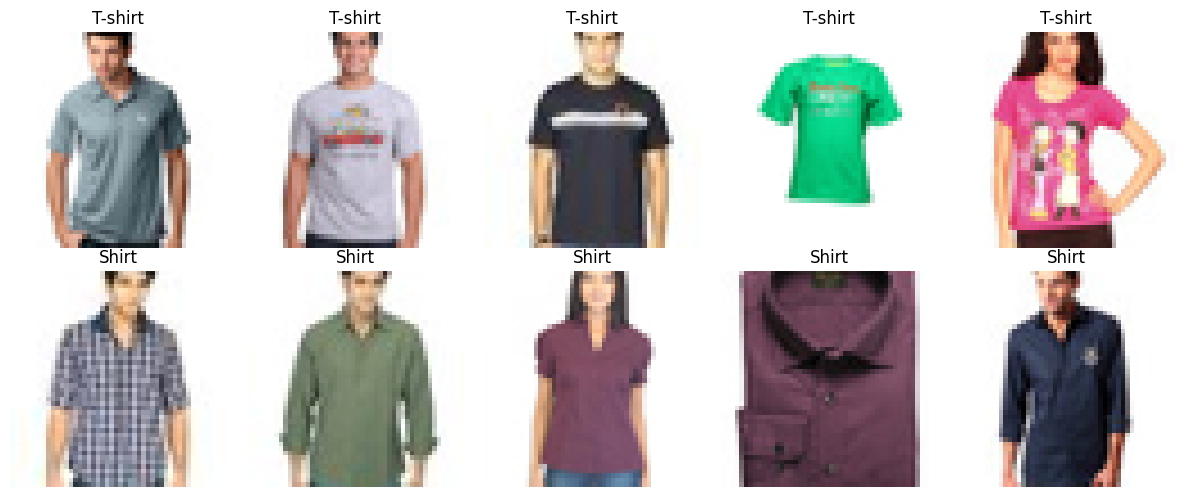

In [19]:

%pip -q install "datasets[vision]" scikit-learn

from datasets import load_dataset
from PIL import ImageOps
import numpy as np
import matplotlib.pyplot as plt

# Loading the Hugging Face dataset
dataset = load_dataset("ashraq/fashion-product-images-small", split="train", streaming=True)

# Defining our two clothing categories
categories = {"Tshirts": 0, "Shirts": 1}
counts = {name: 0 for name in categories}

images = []
labels = []
img_size = 48

# Collecting 100 photographs from each clothing category
for example in dataset:
    category = example["articleType"]

    if category not in categories or counts[category] >= 100:
        continue

    try:
        # Converting, cropping, and resizing the photograph
        image = example["image"].convert("RGB")
        image = ImageOps.fit(image, (img_size, img_size))

        # Converting pixels into numerical values
        pixels = np.asarray(image, dtype=np.float32) / 255.0

        images.append(pixels)
        labels.append(categories[category])
        counts[category] += 1

    except (OSError, ValueError):
        continue

    if all(count == 100 for count in counts.values()):
        break

# Checking the dataset
print("Images per category:", counts)

if not all(count == 100 for count in counts.values()):
    raise ValueError("Could not collect 100 valid images per class.")

images = np.stack(images)
X = images.reshape(len(images), -1)
y = np.array(labels)

print("Image array:", images.shape)
print("PCA input:", X.shape)

# Displaying examples from both categories
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for row, label in enumerate([0, 1]):
    indices = np.where(y == label)[0][:5]

    for col, idx in enumerate(indices):
        axes[row, col].imshow(images[idx])
        axes[row, col].set_title("T-shirt" if label == 0 else "Shirt")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


Step 2 — Inspecting the images
Before fitting PCA, I check a few processed examples from both categories. The sample photographs may differ in lighting, background, and whether a person is wearing the item. These differences can affect PCA because it captures pixel variation, not clothing meaning.

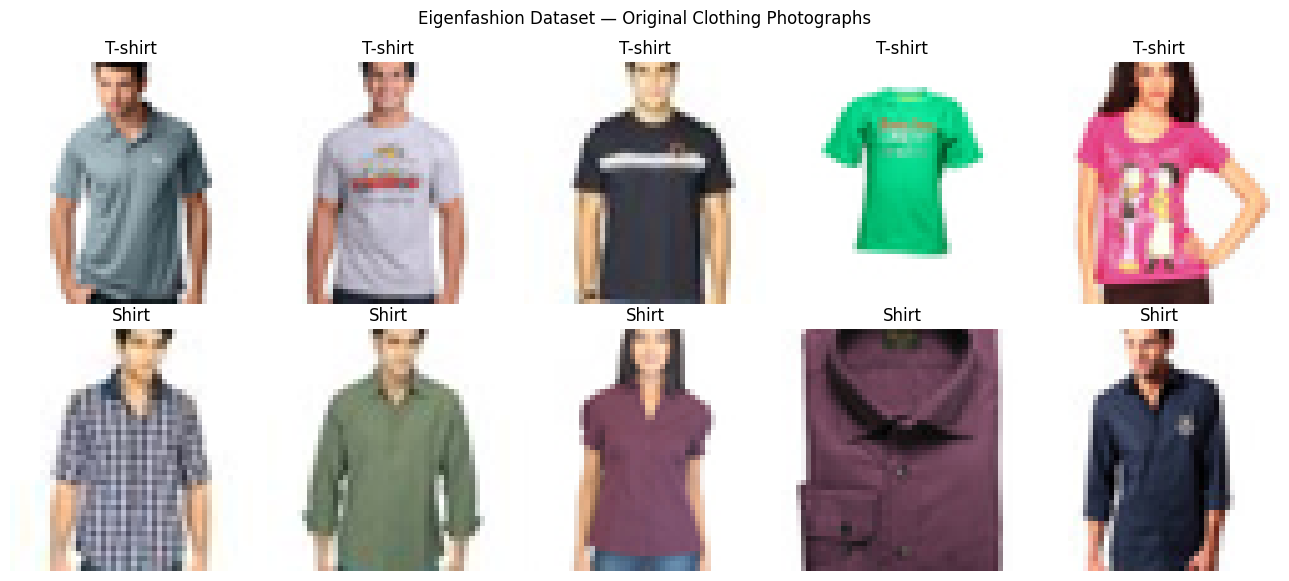

In [20]:
from pathlib import Path

# Preparing a folder for assignment figures
OUTPUT_DIR = Path("/content/eigenfashion_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Confirming the dataset loaded correctly
assert images.shape == (200, 48, 48, 3), f"Unexpected image shape: {images.shape}"
assert X.shape == (200, 6912), f"Unexpected feature matrix: {X.shape}"
assert np.bincount(y, minlength=2).tolist() == [100, 100], "Expected 100 images per class"

# Showing five photographs from each category
fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for row, label in enumerate([0, 1]):
    sample_ids = np.flatnonzero(y == label)[:5]
    for col, image_id in enumerate(sample_ids):
        axes[row, col].imshow(images[image_id])
        axes[row, col].set_title("T-shirt" if label == 0 else "Shirt")
        axes[row, col].axis("off")

fig.suptitle("Eigenfashion Dataset — Original Clothing Photographs")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "01_original_clothing.png", dpi=170, bbox_inches="tight")
plt.show()

Step 3 — Splitting the data before PCA
I reserve 25% of the photographs for testing and use the other 75% for training. I keep the classes balanced by using a stratified split.

I fit PCA only on the training images. If I fit PCA on all 200 photographs before testing a classifier, the test photographs would influence the learned representation; that would cause data leakage.

In [21]:
from sklearn.model_selection import train_test_split

# Splitting indices so that image order remains traceable
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=42)

# Creating the training and testing matrices
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training class counts:", np.bincount(y_train))
print("Testing class counts:", np.bincount(y_test))

Training features: (150, 6912)
Testing features: (50, 6912)
Training class counts: [75 75]
Testing class counts: [25 25]


Step 4 — Performing PCA
PCA finds new, perpendicular directions that capture the greatest variance in the centered data. PC1 captures the greatest variance; PC2 captures the greatest remaining variance, subject to being perpendicular to PC1.

In [22]:
from sklearn.decomposition import PCA

# Fitting PCA only to the training photographs
pca = PCA(svd_solver="full")
pca.fit(X_train)

# Measuring explained variance for each principal component
variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)
k95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)

# Projecting both sets into the learned PCA space
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)

print("Original features per photograph:", X_train.shape[1])
print("Selected number of eigenvectors:", k95)
print(f"Training variance retained: {cumulative_variance[k95 - 1]:.2%}")
print("Reduced training shape:", Z_train[:, :k95].shape)
print("Reduced testing shape:", Z_test[:, :k95].shape)

Original features per photograph: 6912
Selected number of eigenvectors: 68
Training variance retained: 95.10%
Reduced training shape: (150, 68)
Reduced testing shape: (50, 68)


Step 5 — Plotting the cumulative explained variance
I plot the cumulative variance to show why I selected this number of eigenvectors. A lower-dimensional representation keeps fewer features but can lose information from the original pixels.

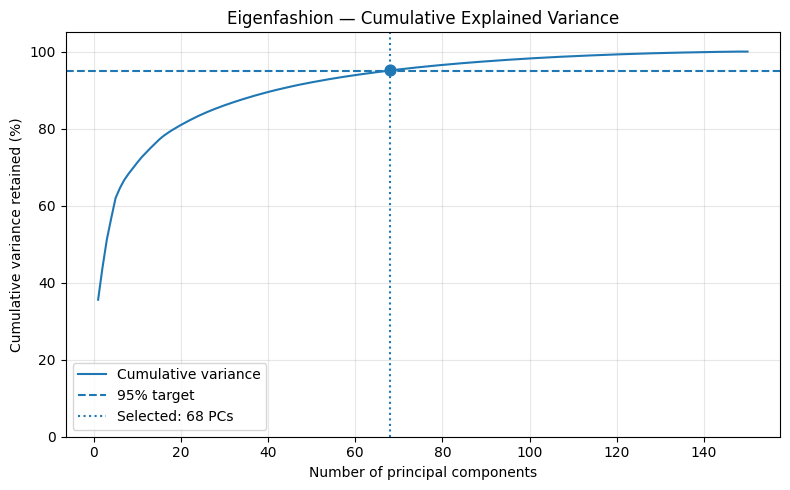

In [23]:
# Plotting the cumulative training variance
fig, ax = plt.subplots(figsize=(8, 5))
component_numbers = np.arange(1, len(cumulative_variance) + 1)

ax.plot(component_numbers, cumulative_variance * 100, label="Cumulative variance")
ax.axhline(95, linestyle="--", label="95% target")
ax.axvline(k95, linestyle=":", label=f"Selected: {k95} PCs")
ax.scatter([k95], [cumulative_variance[k95 - 1] * 100], s=60)
ax.set_title("Eigenfashion — Cumulative Explained Variance")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative variance retained (%)")
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "02_explained_variance.png", dpi=170, bbox_inches="tight")
plt.show()

Step 6 — Visualizing the photographs in the first two principal components
I plot PC1 against PC2 to see how the photographs are arranged in a two-dimensional representation. The labels are shown only for interpretation. Any overlap means the first two components do not completely separate the two clothing classes.

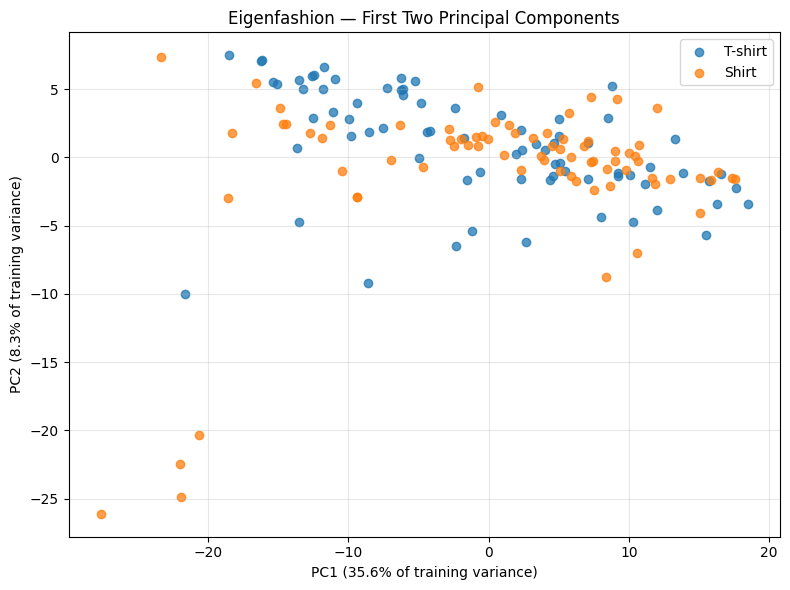

In [24]:
# Comparing the two clothing classes in PCA space
fig, ax = plt.subplots(figsize=(8, 6))

for label, name in [(0, "T-shirt"), (1, "Shirt")]:
    subset = y_train == label
    ax.scatter(Z_train[subset, 0], Z_train[subset, 1], alpha=0.75, label=name)

ax.set_title("Eigenfashion — First Two Principal Components")
ax.set_xlabel(f"PC1 ({variance_ratio[0]:.1%} of training variance)")
ax.set_ylabel(f"PC2 ({variance_ratio[1]:.1%} of training variance)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "03_pca_scatter.png", dpi=170, bbox_inches="tight")
plt.show()

Step 7 — Visualizing eigen-clothing images
A principal component contains one weight for each of the 6,912 pixel features. Reshaping it to 48 × 48 × 3 gives a basis image, sometimes called an eigenimage. I rescale each basis image for display, because PCA component weights are not ordinary RGB pixel values. These images show numerical patterns, not actual pieces of clothing.

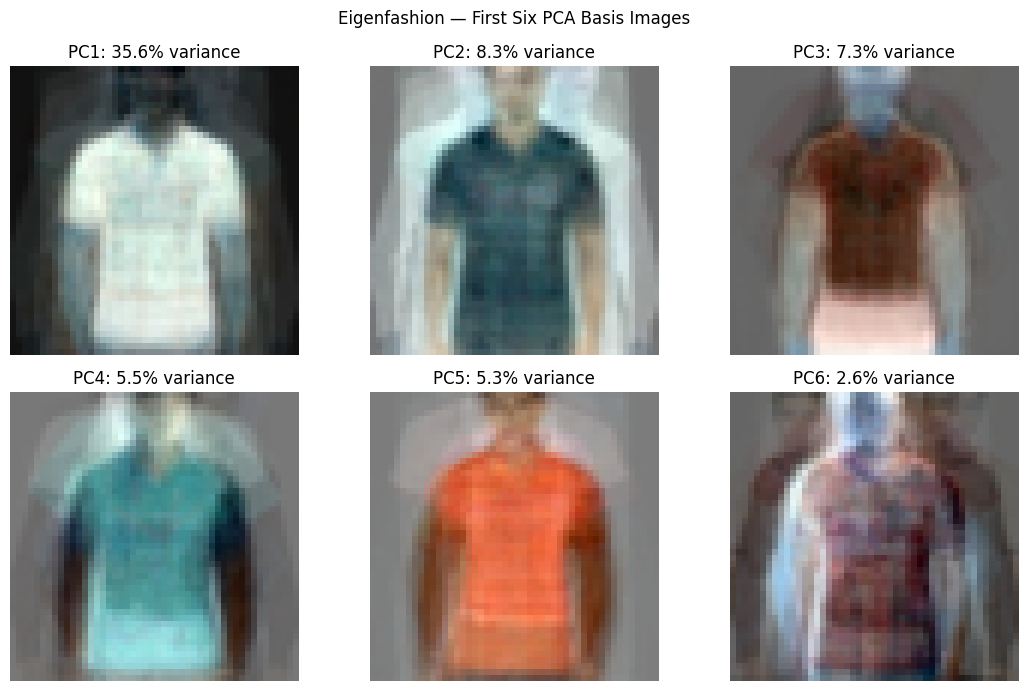

In [25]:
# Visualizing the first six PCA basis vectors
fig, axes = plt.subplots(2, 3, figsize=(11, 7))

for i, ax in enumerate(axes.flat):
    basis = pca.components_[i].reshape(48, 48, 3)

    # Scaling the basis values into displayable RGB values
    lower, upper = basis.min(), basis.max()
    display_basis = (basis - lower) / max(upper - lower, 1e-12)

    ax.imshow(display_basis)
    ax.set_title(f"PC{i + 1}: {variance_ratio[i]:.1%} variance")
    ax.axis("off")

fig.suptitle("Eigenfashion — First Six PCA Basis Images")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "04_eigen_clothing.png", dpi=170, bbox_inches="tight")
plt.show()

Step 8 — Reconstructing images from fewer components I compare original held-out test photographs with reconstructions using 1, 5, 10, and the selected number of principal components. I expect the images to become more detailed as I keep more components. Unlike training images, held-out images generally cannot be reconstructed perfectly even when every training component is used

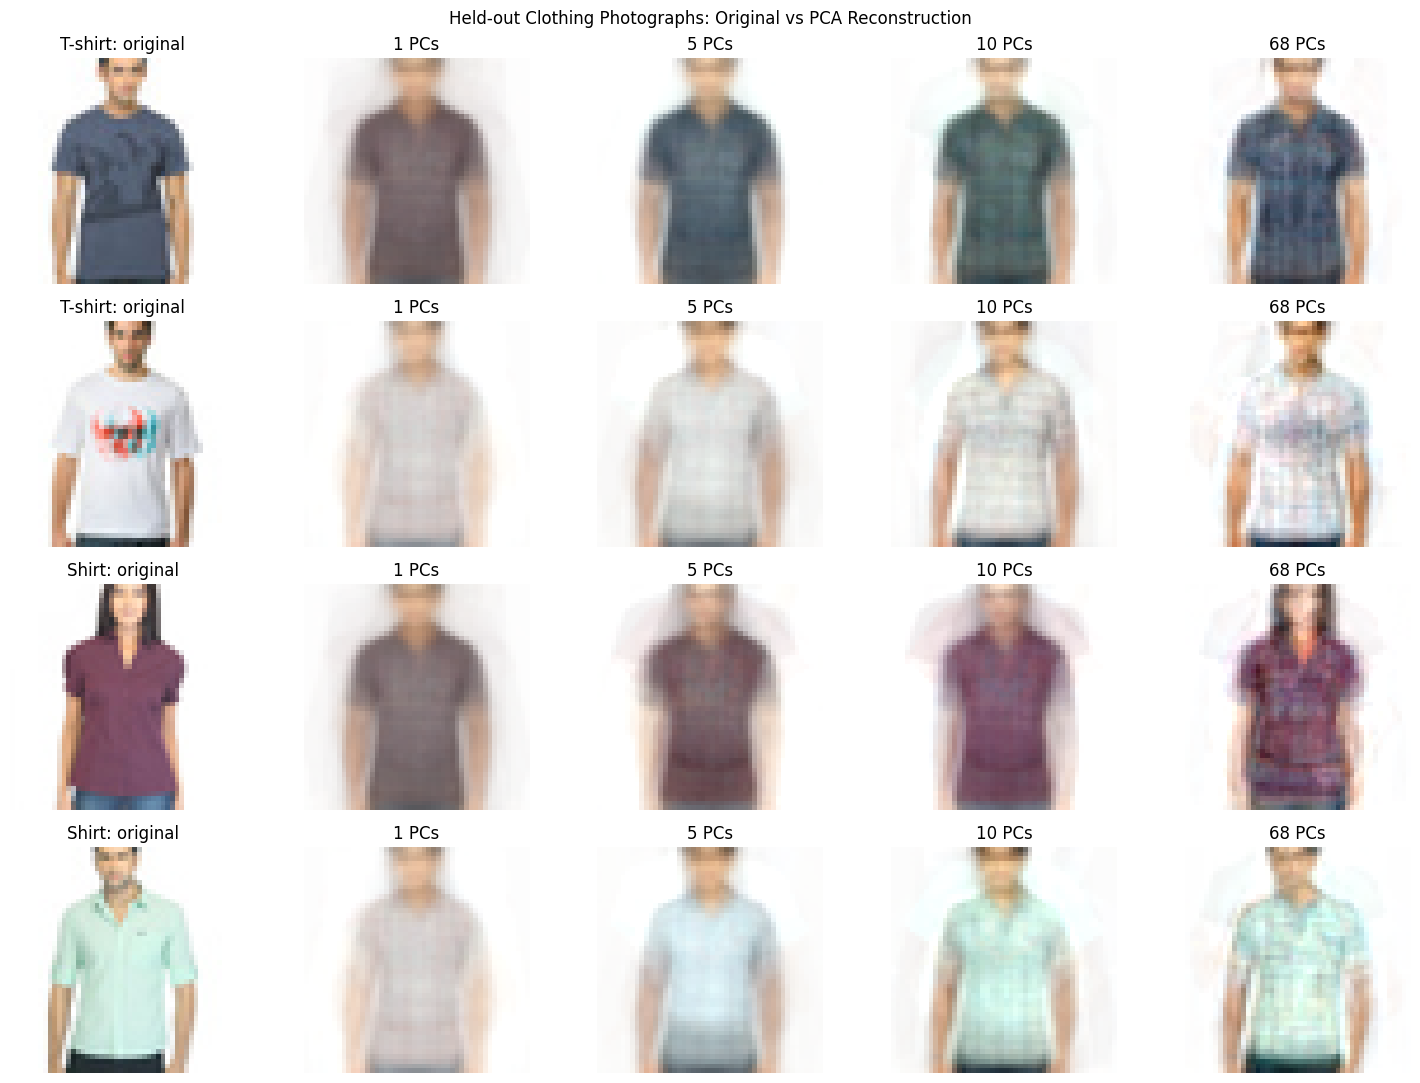

In [26]:
# Reconstructing the held-out test photographs using k components
def reconstruct_test(k):
    flattened = Z_test[:, :k] @ pca.components_[:k] + pca.mean_
    return np.clip(flattened.reshape(-1, 48, 48, 3), 0, 1)

# Comparing several component counts without duplicates
component_counts = list(dict.fromkeys([1, 5, 10, k95]))
reconstructed = {k: reconstruct_test(k) for k in component_counts}
original_test_images = X_test.reshape(-1, 48, 48, 3)

# Selecting two test photographs per category
example_ids = np.concatenate([np.flatnonzero(y_test == 0)[:2], np.flatnonzero(y_test == 1)[:2]])
fig, axes = plt.subplots(len(example_ids), len(component_counts) + 1, figsize=(3 * (len(component_counts) + 1), 11), squeeze=False)

for row, image_id in enumerate(example_ids):
    label = "T-shirt" if y_test[image_id] == 0 else "Shirt"
    axes[row, 0].imshow(original_test_images[image_id])
    axes[row, 0].set_title(f"{label}: original")
    axes[row, 0].axis("off")

    for col, k in enumerate(component_counts, start=1):
        axes[row, col].imshow(reconstructed[k][image_id])
        axes[row, col].set_title(f"{k} PCs")
        axes[row, col].axis("off")

fig.suptitle("Held-out Clothing Photographs: Original vs PCA Reconstruction")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "05_reconstructions.png", dpi=170, bbox_inches="tight")
plt.show()

Step 9 — Measuring reconstruction error

In [27]:
# Measuring how well the test photographs are reconstructed
for k in component_counts:
    mse = np.mean((original_test_images - reconstructed[k]) ** 2)
    print(f"{k:3d} components | test reconstruction MSE: {mse:.6f}")

  1 components | test reconstruction MSE: 0.027055
  5 components | test reconstruction MSE: 0.017648
 10 components | test reconstruction MSE: 0.014631
 68 components | test reconstruction MSE: 0.008178


Step 10 — Testing a binary classifier on PCA features
The assignment asks me to choose a binary classification task. I use logistic regression to predict T-shirt (0) or Shirt (1) from the reduced PCA representation. I standardize the PCA scores using only the training data, then evaluate on the 50 unseen test photographs.

I also compare the result to a simple baseline classifier that predicts the most frequent training class. PCA itself remains unsupervised; logistic regression is a separate supervised step.

PCA + logistic regression accuracy: 0.780
PCA + logistic regression balanced accuracy: 0.780
Majority-class baseline accuracy: 0.500

Classification report:
              precision    recall  f1-score   support

     T-shirt       0.77      0.80      0.78        25
       Shirt       0.79      0.76      0.78        25

    accuracy                           0.78        50
   macro avg       0.78      0.78      0.78        50
weighted avg       0.78      0.78      0.78        50



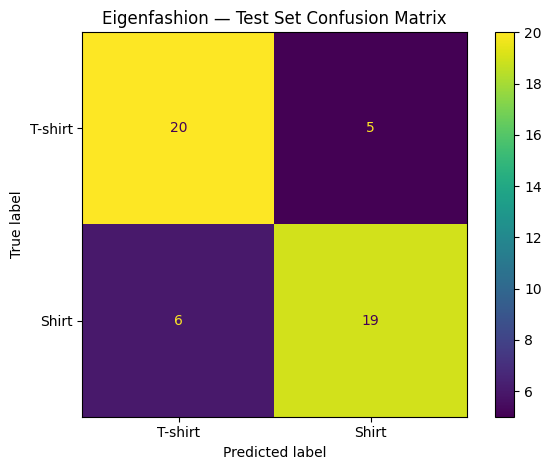

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay

# Selecting PCA scores from the chosen components
train_features = Z_train[:, :k95]
test_features = Z_test[:, :k95]

# Training a logistic regression model on the reduced features
classifier = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=42))
classifier.fit(train_features, y_train)
predictions = classifier.predict(test_features)

# Comparing the model to a simple majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(train_features, y_train)
baseline_predictions = baseline.predict(test_features)

accuracy = accuracy_score(y_test, predictions)
balanced_accuracy = balanced_accuracy_score(y_test, predictions)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(f"PCA + logistic regression accuracy: {accuracy:.3f}")
print(f"PCA + logistic regression balanced accuracy: {balanced_accuracy:.3f}")
print(f"Majority-class baseline accuracy: {baseline_accuracy:.3f}")
print("\nClassification report:")
print(classification_report(y_test, predictions, target_names=["T-shirt", "Shirt"], zero_division=0))

# Visualizing test classification outcomes
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=[0, 1], display_labels=["T-shirt", "Shirt"])
plt.title("Eigenfashion — Test Set Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_confusion_matrix.png", dpi=170, bbox_inches="tight")
plt.show()

Step 11 — Reporting the measured results
These values are calculated by the notebook, rather than assumed in advance. I will use them in the assignment response. I will also discuss the limitations: backgrounds, lighting, and photographs of models can influence PCA; the two classes can overlap visually; and a 50-image test set gives an uncertain estimate of classification accuracy.

In [29]:
# Summarizing the outputs for the assignment
print("EIGENFASHION RESULTS")
print("Dataset: Hugging Face replacement for inaccessible ImageNet links")
print("Categories: 100 T-shirts and 100 shirts")
print("Original features per image:", X.shape[1])
print("Training images:", len(train_idx))
print("Test images:", len(test_idx))
print("Selected eigenvectors:", k95)
print(f"Training variance retained: {cumulative_variance[k95 - 1]:.2%}")
print(f"Test accuracy: {accuracy:.2%}")
print(f"Test balanced accuracy: {balanced_accuracy:.2%}")
print(f"Baseline accuracy: {baseline_accuracy:.2%}")
print("Figures saved to:", OUTPUT_DIR)

EIGENFASHION RESULTS
Dataset: Hugging Face replacement for inaccessible ImageNet links
Categories: 100 T-shirts and 100 shirts
Original features per image: 6912
Training images: 150
Test images: 50
Selected eigenvectors: 68
Training variance retained: 95.10%
Test accuracy: 78.00%
Test balanced accuracy: 78.00%
Baseline accuracy: 50.00%
Figures saved to: /content/eigenfashion_results


# Extension Questions: Berlin Wall Paintings and PCA
Assignment: Load 10 original phone photographs, save them as a numerical array, and perform PCA with scikit-learn.

Research question: How effectively can PCA reduce the dimensionality of photographs of Berlin Wall paintings while preserving their major visual features?

The photographs are unlabeled. PCA is unsupervised; a binary classifier is not required for this extension.

Run the cells in order. Change only IMAGE_DIR in Cell 2 to the location of your photographs in Google Drive.

1. Connecting Google Colab to Google Drive
Google Drive already hosts your photos, so you do not need curl or public image URLs. Run this cell and authorize access to the account containing your images. The pillow-heif package allows Colab to read HEIC/HEIF images taken on some phones.

In [30]:
%pip -q install pillow-heif

from google.colab import drive
from pathlib import Path

# Connecting Colab to Google Drive
drive.mount("/content/drive")

# Setting the folder containing the photographs
IMAGE_DIR = Path("/content/drive/MyDrive/Cs156 pcw")

# Setting a separate folder for the output files
OUTPUT_DIR = Path("/content/drive/MyDrive/CS156_Session16_Berlin_Wall_PCA_Results")

# Checking that the source folder exists
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Image folder not found: {IMAGE_DIR}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Image folder:", IMAGE_DIR)
print("Results folder:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Image folder: /content/drive/MyDrive/Cs156 pcw
Results folder: /content/drive/MyDrive/CS156_Session16_Berlin_Wall_PCA_Results


Step 2. Cropping, resizing, and converting images into numerical arrays
Phone photographs can have different sizes and orientations. I correct orientation, convert to RGB, center-crop and resize each photograph to 64 × 64 pixels, and scale pixel values from 0–255 to 0–1. Each photograph is then represented by a vector of \(64\times64\times3=12,288\) features. The resulting matrix \(X\) has shape \((10,12,288)\).

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener

# Enabling support for iPhone HEIC and HEIF photographs
register_heif_opener()

# Finding supported images, including those in subfolders
extensions = {".jpg", ".jpeg", ".png", ".webp", ".heic", ".heif"}
paths = sorted(p for p in IMAGE_DIR.rglob("*") if p.is_file() and p.suffix.lower() in extensions)

print("Image files found:", len(paths))
for path in paths:
    print("-", path.relative_to(IMAGE_DIR))

if len(paths) < 10:
    raise ValueError("At least 10 image files are needed. Check the Google Drive folder.")
if len(paths) > 10:
    print("More than 10 files found. Using the first 10 valid images in alphabetical order.")

images = []
filenames = []
img_size = 64

for path in paths:
    try:
        # Reading and correcting the original photograph
        with Image.open(path) as source:
            img = ImageOps.exif_transpose(source).convert("RGB")

            # Center-cropping and resizing to a common size
            img = ImageOps.fit(img, (img_size, img_size), method=Image.Resampling.LANCZOS)

            # Scaling pixel values to the interval from 0 to 1
            pixels = np.asarray(img, dtype=np.float32) / 255.0

        images.append(pixels)
        filenames.append(str(path.relative_to(IMAGE_DIR)))

        if len(images) == 10:
            break
    except (OSError, ValueError) as error:
        print(f"Skipping {path.name}: {error}")

if len(images) != 10:
    raise ValueError(f"Only {len(images)} readable photographs were found; 10 are required.")

# Stacking images and flattening the pixels for PCA
images = np.stack(images)
X = images.reshape(len(images), -1)

print("Images array shape:", images.shape)
print("PCA matrix shape:", X.shape)
print("Pixel value range:", float(X.min()), "to", float(X.max()))

Image files found: 10
- IMG_20261101_144201.jpg
- IMG_20261101_144244.jpg
- IMG_20261101_144350.jpg
- IMG_20261101_144521.jpg
- IMG_20261101_144542.jpg
- IMG_20261101_144636.jpg
- IMG_20261101_145010.jpg
- IMG_20261101_145023.jpg
- IMG_20261101_145555.jpg
- IMG_20261101_150055.jpg
Images array shape: (10, 64, 64, 3)
PCA matrix shape: (10, 12288)
Pixel value range: 0.0 to 1.0


Step 3. Visualizing the processed photographs
Before PCA, I check that all 10 photographs loaded correctly. The figure also provides a record of the original images after resizing, but before PCA reconstruction.

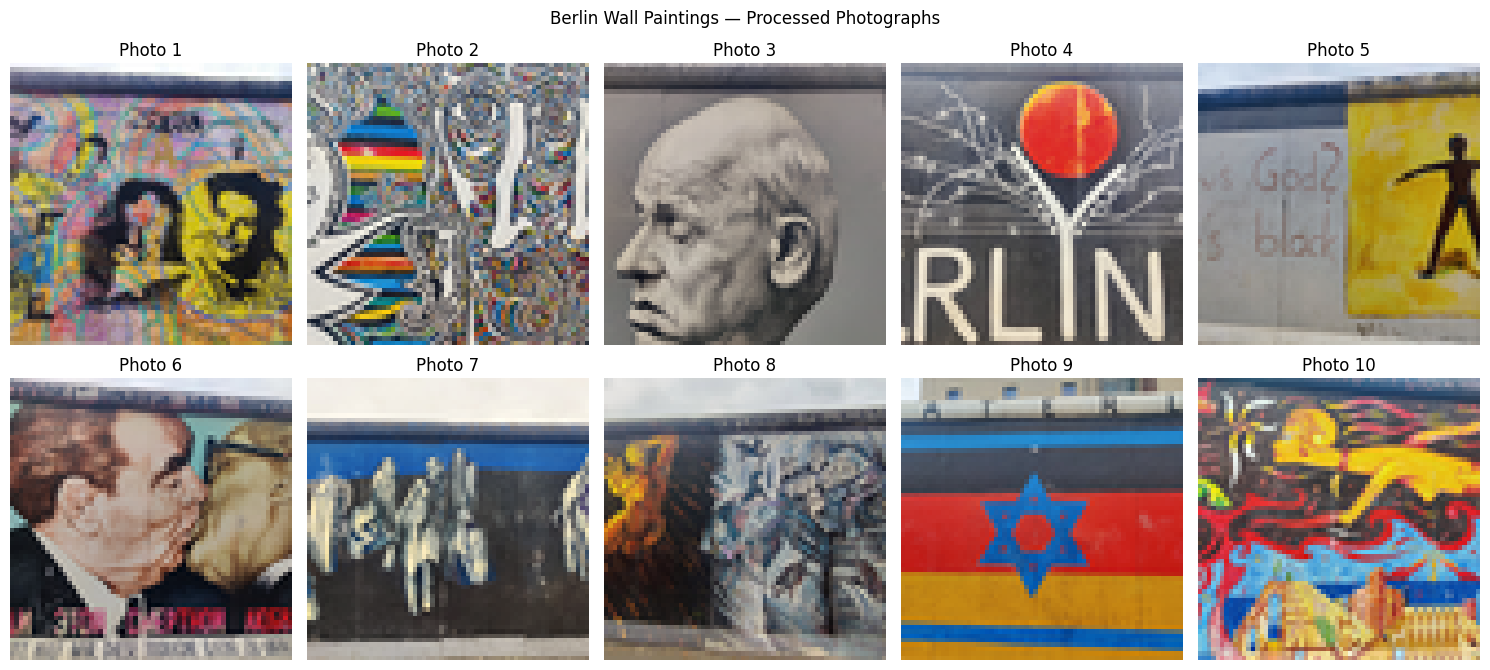

In [32]:
# Plotting all 10 processed photographs
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.set_title(f"Photo {i + 1}")
    ax.axis("off")

fig.suptitle("Berlin Wall Paintings — Processed Photographs")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "01_original_images.png", dpi=160, bbox_inches="tight")
plt.show()

Step 4. Finding principal components
PCA centers the pixel values and identifies orthogonal directions that capture the greatest variation across photographs. PC1 captures the most variance; PC2 captures the most remaining variance while being perpendicular to PC1.

For centered data, the first principal direction maximizes the variance of the projection formula. With only 10 photographs, there can be at most 9 principal components with nonzero variance. The number of components used for a smaller representation is chosen from explained variance, not guessed in advance.

In [33]:
from sklearn.decomposition import PCA

# Fitting PCA to the 10 unlabeled photographs
pca = PCA(n_components=min(len(X) - 1, X.shape[1]), svd_solver="full")
scores = pca.fit_transform(X)

# Measuring the variance explained by each component
variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)

if not np.all(np.isfinite(variance)):
    raise ValueError("PCA variance is undefined. Check whether the photographs are identical.")

# Selecting the smallest number of components that preserve at least 90% variance
k90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)

print("Original features per photograph:", X.shape[1])
print("Available principal components:", len(variance))
print("Components needed for at least 90% variance:", k90)
print(f"Cumulative variance retained: {cumulative_variance[k90 - 1]:.2%}")
print("Reduced data shape:", scores[:, :k90].shape)

Original features per photograph: 12288
Available principal components: 9
Components needed for at least 90% variance: 8
Cumulative variance retained: 94.97%
Reduced data shape: (10, 8)


Step 5. Plotting cumulative explained variance
A cumulative explained-variance curve shows how much of the dataset's variation is retained when we keep the first k component, I select the first k components for which this fraction reaches at least 90%. A larger k preserves more variance but reduces dimensionality less.

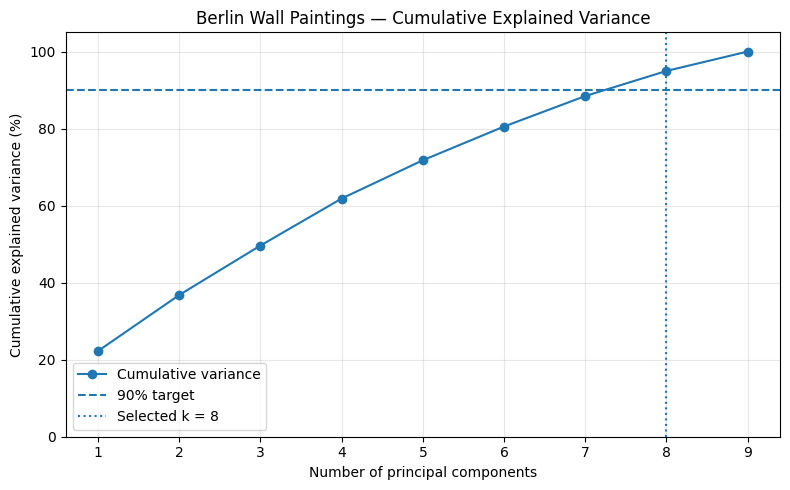

In [34]:
# Plotting cumulative explained variance
counts = np.arange(1, len(variance) + 1)
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(counts, cumulative_variance * 100, marker="o", label="Cumulative variance")
ax.axhline(90, linestyle="--", label="90% target")
ax.axvline(k90, linestyle=":", label=f"Selected k = {k90}")
ax.set_title("Berlin Wall Paintings — Cumulative Explained Variance")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance (%)")
ax.set_xticks(counts)
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "02_explained_variance.png", dpi=160, bbox_inches="tight")
plt.show()

Step 6. Visualizing the 10 photographs in PCA space
I plot the photographs using their coordinates on PC1 and PC2. Images that appear close together have similar scores along these two directions. Because these are only two of the possible components, distances in this plot do not capture every visual difference.

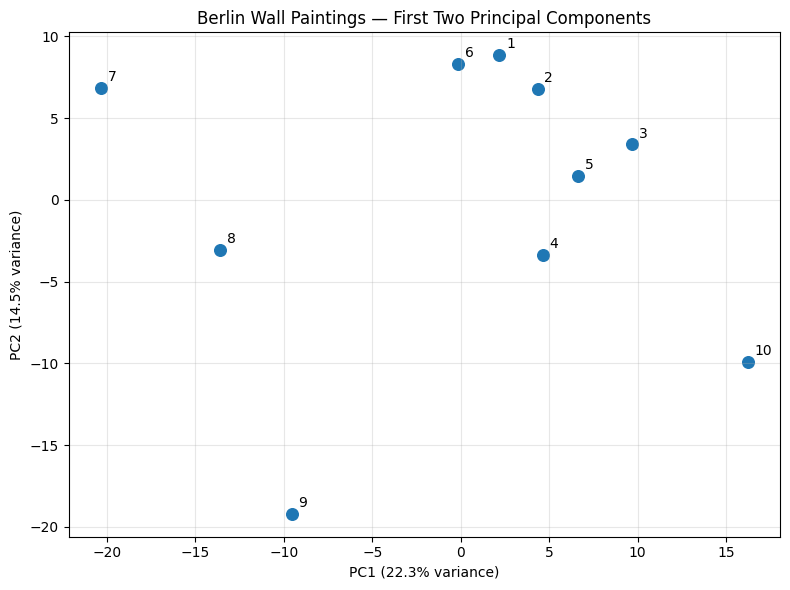

In [35]:
# Visualizing the images using their first two PCA scores
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(scores[:, 0], scores[:, 1], s=70)

for i in range(len(scores)):
    ax.annotate(f"{i + 1}", (scores[i, 0], scores[i, 1]), xytext=(5, 5), textcoords="offset points")

ax.set_xlabel(f"PC1 ({variance[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({variance[1]:.1%} variance)")
ax.set_title("Berlin Wall Paintings — First Two Principal Components")
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "03_pca_scatterplot.png", dpi=160, bbox_inches="tight")
plt.show()

Step 7. Viewing the basis images (eigenimages)
Each PCA basis vector contains one weight for each pixel and color channel. Reshaping it into a 64 × 64 RGB array shows the pattern of pixel variation represented by that component. The display is contrast-scaled for visibility, so these are not reconstructed paintings or actual color photographs.

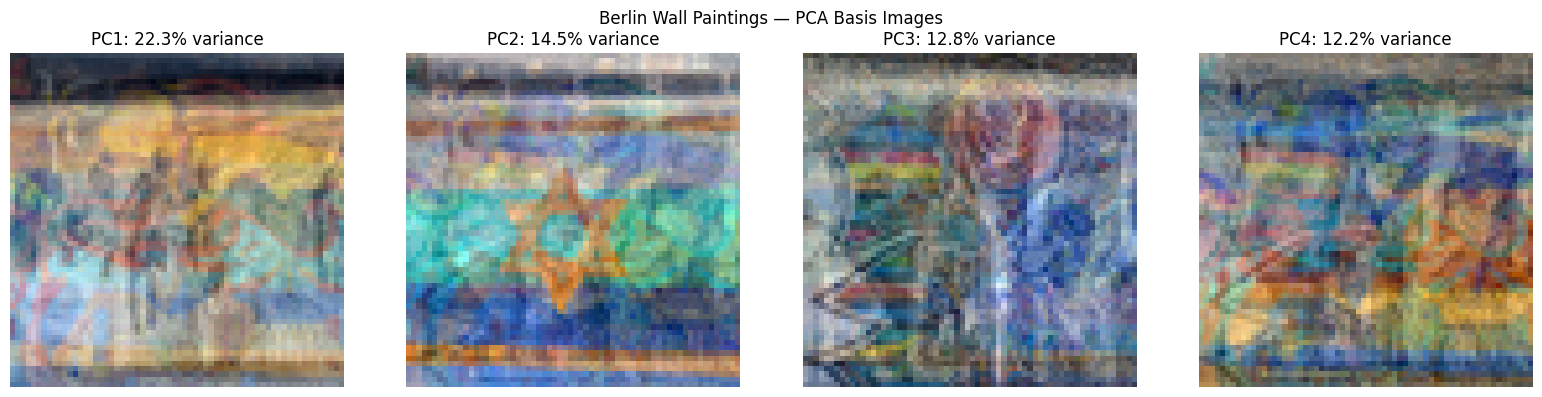

In [36]:
# Displaying the first four PCA basis images
n_show = min(4, len(variance))
fig, axes = plt.subplots(1, n_show, figsize=(4 * n_show, 4))

for i, ax in enumerate(np.atleast_1d(axes)):
    basis = pca.components_[i].reshape(img_size, img_size, 3)

    # Rescaling each basis vector for display only
    smallest = float(basis.min())
    largest = float(basis.max())
    display_basis = (basis - smallest) / max(largest - smallest, 1e-12)

    ax.imshow(display_basis)
    ax.set_title(f"PC{i + 1}: {variance[i]:.1%} variance")
    ax.axis("off")

fig.suptitle("Berlin Wall Paintings — PCA Basis Images")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "04_pca_basis_images.png", dpi=160, bbox_inches="tight")
plt.show()

Step 8. Reconstructing the photographs with fewer components
A reconstruction approximates an image using the dataset's mean image and a weighted sum of the retained components. I compare the original photographs with reconstructions using 1, 2, 5, and k_90components, as well as all available components. With fewer components, some fine details may be lost. Using all nonzero components can closely reproduce the 10 photographs used to fit PCA.

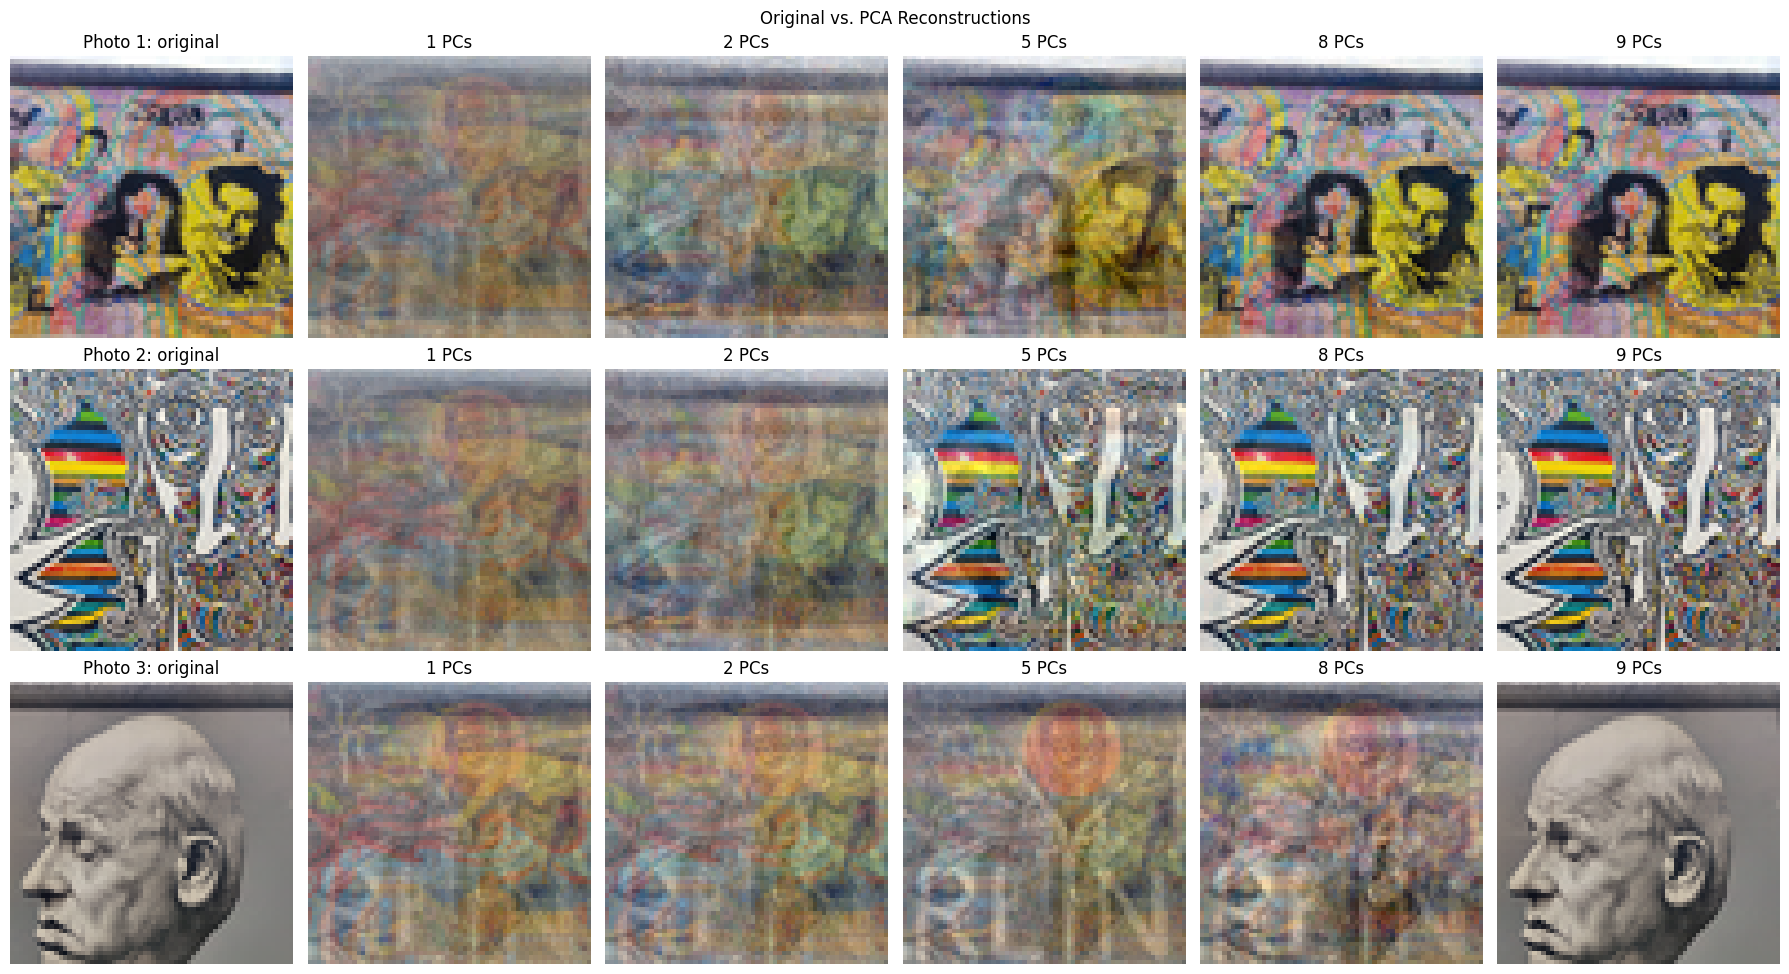

In [37]:
# Defining a function for reconstructing images using k components
def reconstruct_images(k):
    reconstructed = scores[:, :k] @ pca.components_[:k] + pca.mean_
    return np.clip(reconstructed.reshape(images.shape), 0, 1)

# Preparing several levels of image reconstruction
component_counts = list(dict.fromkeys([1, 2, 5, k90, len(variance)]))
reconstructions = {k: reconstruct_images(k) for k in component_counts}
example_ids = [0, 1, 2]

# Comparing original and reconstructed versions of three photographs
fig, axes = plt.subplots(len(example_ids), len(component_counts) + 1, figsize=(3 * (len(component_counts) + 1), 10), squeeze=False)

for row, image_id in enumerate(example_ids):
    axes[row, 0].imshow(images[image_id])
    axes[row, 0].set_title(f"Photo {image_id + 1}: original")
    axes[row, 0].axis("off")

    for col, k in enumerate(component_counts, start=1):
        axes[row, col].imshow(reconstructions[k][image_id])
        axes[row, col].set_title(f"{k} PCs")
        axes[row, col].axis("off")

fig.suptitle("Original vs. PCA Reconstructions")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "05_pca_reconstructions.png", dpi=160, bbox_inches="tight")
plt.show()

Step 9. Measuring reconstruction error
Mean squared error (MSE) measures the average squared difference between original and reconstructed pixel values. A smaller MSE means the reconstructed pixels are closer to the original pixels. This is an in-sample reconstruction measure, not a test of generalization to new photographs.

In [38]:
# Calculating the mean squared reconstruction error
for k in component_counts:
    mse = np.mean((images - reconstructions[k]) ** 2)
    print(f"{k} components: reconstruction MSE = {mse:.6f}")

1 components: reconstruction MSE = 0.032233
2 components: reconstruction MSE = 0.026183
5 components: reconstruction MSE = 0.011691
8 components: reconstruction MSE = 0.002086
9 components: reconstruction MSE = 0.000000


In [39]:
# Saving processed arrays and fitted PCA results to Google Drive
np.savez_compressed(
    OUTPUT_DIR / "berlin_wall_pca_dataset.npz",
    images=images,
    X=X,
    filenames=np.asarray(filenames),
    scores=scores,
    components=pca.components_,
    mean_image=pca.mean_,
    explained_variance_ratio=variance,
    cumulative_explained_variance=cumulative_variance,
    selected_components=k90)

print("Saved arrays and figures to:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Saved arrays and figures to: /content/drive/MyDrive/CS156_Session16_Berlin_Wall_PCA_Results
- 01_original_images.png
- 02_explained_variance.png
- 03_pca_scatterplot.png
- 04_pca_basis_images.png
- 05_pca_reconstructions.png
- berlin_wall_pca_dataset.npz
